# 03 · Signatures — embryonic-development module geography & Gate 2

The three embryonic modules (**Gast** gastrulation, **pSom** posterior somitogenesis,
**Crest** neural crest) were scored in 02 against the shared **union** control pool and
graph-smoothed. **Gate 2** reads the module geography off the signature embeddings: does the
embryonic pattern appear? For a **non-branching** manifold the criterion (§1) is a single
developmental axis with Gast/pSom overlap and **Crest as an inverse/terminal gradient** — which
still **passes (GO)**, with Gate 3 = NA. We render the raw per-cell signature maps (the
deliverables) and quantify the geography that underpins the call.

In [1]:
import os, sys, glob
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
import numpy as np, pandas as pd
import scanpy as sc, scanpy.external as sce, scFates as scf
import matplotlib.pyplot as plt
from scipy.stats import spearmanr
sc.settings.verbosity = 1
SEED = 1; np.random.seed(SEED)

In [2]:
name = os.path.basename(os.getcwd())
cat  = os.path.basename(os.path.dirname(os.getcwd()))
pth  = os.path.join(*([os.pardir]*6))
pth_data = os.path.join(pth, 'data')
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)
pth_fig = os.path.join(pth, 'figures', 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)
pth_cb  = os.path.join(pth_fig, 'colorbars')
os.makedirs(pth_out, exist_ok=True); os.makedirs(pth_cb, exist_ok=True)

### Load the rooted manifold (signatures scored + smoothed in 02)

In [3]:
adata = sc.read_h5ad(os.path.join(pth_out, 'manifold.h5ad'))
print('cells:', adata.shape[0], '| scores present:', [m for m in ['Gast','pSom','Crest'] if m in adata.obs])
pth_feat = os.path.join(pth_data, 'features', 'biomart')
feat = {os.path.basename(f).replace('.csv',''): pd.read_csv(f).hsapiens.drop_duplicates()
        for f in sorted(glob.glob(os.path.join(pth_feat,'*.csv')))}
for src,lab in [('GSE162534','Gast'),('GSE229103','pSom'),('rRNAModifications','Crest')]:
    g = feat[src].loc[feat[src].isin(adata.var_names)]
    print(f'{lab}: {g.size}/{feat[src].size} genes present')

cells: 10368 | scores present: ['Gast', 'pSom', 'Crest']
Gast: 77/81 genes present
pSom: 92/98 genes present
Crest: 101/104 genes present


### Gate 2 — module geography on the manifold
Quantitative test of the non-branching signature: (i) the dominant developmental contrast is
**Gast/pSom vs Crest** (both modules anti-correlate strongly with Crest in space); (ii) Gast
and pSom **overlap** (weak mutual anti-correlation, no competing-arm separation); (iii) along
pseudotime Gast declines and Crest rises, with the neural-crest-high decile at the terminus;
(iv) a joint-high enrichment test confirms Crest is an **inverse gradient**, not a co-expression
hub. Crest is terminal to **both** modules (canonical orientation) — no Crest-arm inversion flag.

In [4]:
print('smoothed spatial correlations (geography):')
for a,b in [('Gast_sm','pSom_sm'),('Gast_sm','Crest_sm'),('pSom_sm','Crest_sm')]:
    print(f'  {a} vs {b}: r = {np.corrcoef(adata.obs[a], adata.obs[b])[0,1]:+.2f}')
t = adata.obs['t'].values; tn = (t-t.min())/(t.max()-t.min())
print('gradient along pseudotime (Spearman rho on smoothed):')
for s in ['Gast_sm','pSom_sm','Crest_sm']:
    rho,_ = spearmanr(t, adata.obs[s]); print(f'  {s}: rho = {rho:+.3f}')
hi = adata.obs['Crest_sm'] >= adata.obs['Crest_sm'].quantile(0.9)
print(f'Neural-crest-high decile mean pseudotime = {tn[hi.values].mean():.2f} (terminal if ~1)')
lo = adata.obs['Gast_sm'] >= adata.obs['Gast_sm'].quantile(0.9)
print(f'Gastrulation-high decile mean pseudotime = {tn[lo.values].mean():.2f} (origin if ~0)')
# inverse-gradient vs co-expression-hub test (Gast&Crest and pSom&Crest joint-high enrichment)
def enrich(m1,m2):
    z1=(adata.obs[m1]-adata.obs[m1].mean())/adata.obs[m1].std()
    z2=(adata.obs[m2]-adata.obs[m2].mean())/adata.obs[m2].std()
    joint=((z1>0.5)&(z2>0.5)).mean(); exp=(z1>0.5).mean()*(z2>0.5).mean()
    return joint/exp
print(f'Gast&Crest joint-high enrichment = {enrich("Gast","Crest"):.2f}; pSom&Crest = {enrich("pSom","Crest"):.2f} (<1 = inverse gradient)')
print('Gate 2: single developmental axis, Gast/pSom overlap, Crest terminal inverse gradient -> GO (non-branching)')
print('Gate 3: no bifurcation -> NA. Crest terminal to both modules -> no Crest-arm inversion flag.')

smoothed spatial correlations (geography):
  Gast_sm vs pSom_sm: r = -0.11
  Gast_sm vs Crest_sm: r = -0.53
  pSom_sm vs Crest_sm: r = -0.38
gradient along pseudotime (Spearman rho on smoothed):
  Gast_sm: rho = -0.580
  pSom_sm: rho = +0.185
  Crest_sm: rho = +0.425
Neural-crest-high decile mean pseudotime = 0.75 (terminal if ~1)
Gastrulation-high decile mean pseudotime = 0.24 (origin if ~0)
Gast&Crest joint-high enrichment = 0.31; pSom&Crest = 0.44 (<1 = inverse gradient)
Gate 2: single developmental axis, Gast/pSom overlap, Crest terminal inverse gradient -> GO (non-branching)
Gate 3: no bifurcation -> NA. Crest terminal to both modules -> no Crest-arm inversion flag.


### Per-module signature figures + colorbars (deliverable)
House style: `figsize=(3.5,1.5)`, pseudotime left→right (`X_umap_lin`), `size=30`, plasma,
**raw** (not smoothed) per-cell score so 10x dropout is honestly visible. Colorbar ticks are
data-driven (min→max).

saved Gast_signature.pdf + colorbar
saved pSom_signature.pdf + colorbar
saved Crest_signature.pdf + colorbar


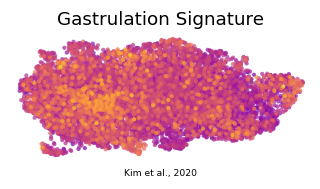

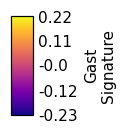

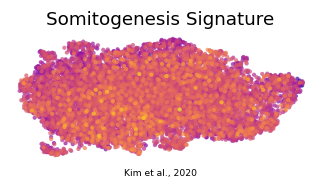

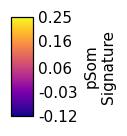

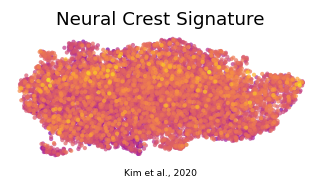

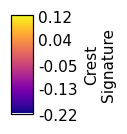

In [5]:
plot = adata.copy(); plot.obsm['X_umap'] = plot.obsm['X_umap_lin']
xl = plot.obsm['X_umap']
xlo,xhi = np.percentile(xl[:,0],[0.3,99.7]); ylo,yhi = np.percentile(xl[:,1],[0.3,99.7])
px=(xhi-xlo)*.05; py=(yhi-ylo)*.08
titles = {'Gast':'Gastrulation Signature','pSom':'Somitogenesis Signature','Crest':'Neural Crest Signature'}
for m in ['Gast','pSom','Crest']:
    fig, ax = plt.subplots(figsize=(3.5,1.5))
    sc.pl.umap(plot, color=m, cmap='plasma', alpha=.7, size=30, colorbar_loc=None,
               frameon=False, show=False, ax=ax, title=titles[m])
    ax.set_xlim(xlo-px,xhi+px); ax.set_ylim(ylo-py,yhi+py)
    ax.text(.5,-.12,'Kim et al., 2020', ha='center', transform=ax.transAxes, size=6)
    fig.savefig(os.path.join(pth_fig, f'{m}_signature.pdf'), bbox_inches='tight')
    lo_, hi_ = float(adata.obs[m].min()), float(adata.obs[m].max())
    ticks = np.round(np.linspace(lo_, hi_, 5), 2)
    fcb = plt.figure(figsize=(.66,1)); cax = fcb.add_axes([.35,.05,.3,.9])
    cb = plt.colorbar(ax.collections[0], cax=cax); cb.ax.tick_params(which='both', size=0)
    cb.set_label(f'{m}\nSignature'); cb.set_ticks(ticks, labels=ticks); cb.solids.set_alpha(1)
    fcb.savefig(os.path.join(pth_cb, f'{m}_colorbar.pdf'), bbox_inches='tight')
    print('saved', f'{m}_signature.pdf', '+ colorbar')

### Save signatures data

In [6]:
adata.write(os.path.join(pth_out, 'signatures.h5ad'))
print('saved signatures.h5ad', adata.shape)

saved signatures.h5ad (10368, 17954)
